# Lab01 - sprint 1

## Random Variable 03 (r_def)

### Description

<!-- ТЕКСТ ПИШЕТ ДАРЬЯ: Description (что такое центроид и r_def, смысл значений около 0 и 1, данные, почему величина случайная) -->

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# константы
SEED = 42
N_REP = 100        # повторов на размер выборки (состоятельность)
N_SAMPLE = 1000    # размер выборки с возвращением / без
N_MC = 500         # повторов Монте-Карло для sd среднего
N_GOF = 2000       # подвыборка для goodness_of_fit
B_GOF = 200        # n_mc_samples для goodness_of_fit
K_CHI2 = 20        # число равновероятных интервалов для chi2
EPS = 1e-6         # обрезка 0 и 1

rng = np.random.default_rng(SEED)

In [2]:
df = pd.read_parquet("../wm811k_features.parquet")
x_all = df["r_def"]
x = x_all.dropna()
print("df.shape =", df.shape)
print("dieSize =", df["dieSize"].iloc[0], "| число лотов =", df["lotName"].nunique())
print(f"r_def определена: {len(x)} из {len(x_all)}, выпало {x_all.isna().mean():.4%}")
print("точных 0:", int((x == 0).sum()), "| точных 1:", int((x == 1).sum()))
print("n_defect == 1:", int((df["n_defect"] == 1).sum()), "| n_defect >= 2:", int((df["n_defect"] >= 2).sum()),
      "| min n_defect:", df["n_defect"].min())
x.describe()

df.shape = (15881, 11)
dieSize = 516.0 | число лотов = 715
r_def определена: 15881 из 15881, выпало 0.0000%
точных 0: 0 | точных 1: 0
n_defect == 1: 0 | n_defect >= 2: 15881 | min n_defect: 49


count    15881.000000
mean         0.070453
std          0.037101
min          0.001277
25%          0.042462
50%          0.066077
75%          0.093726
max          0.256344
Name: r_def, dtype: float64

#### Случайность: разброс внутри лотов

In [3]:
by_lot = df.dropna(subset=["r_def"]).groupby("lotName")["r_def"].agg(["count", "min", "max", "mean", "std"])
by_lot[by_lot["count"] >= 10].head(10)

,count,min,max,mean,std
lotName,,,,,
lot42869,23,0.003087,0.150390,0.068340,0.037052
lot42870,25,0.017336,0.159438,0.062587,0.033798
lot42871,21,0.009933,0.116662,0.064207,0.028393
lot42872,23,0.005161,0.164861,0.056299,0.037681
lot42873,21,0.010791,0.124241,0.056179,0.032151
lot42874,24,0.027964,0.137051,0.075958,0.028329
lot42875,23,0.027956,0.151073,0.071685,0.031173
lot42876,23,0.021081,0.122694,0.065492,0.023772
lot42877,25,0.020002,0.152667,0.070106,0.037416


In [4]:
# разложение дисперсии: внутри лотов и между лотами
g = df.dropna(subset=["r_def"]).groupby("lotName")["r_def"]
var_within = (g.var(ddof=1).fillna(0) * (g.size() - 1)).sum() / (len(x) - g.ngroups)
var_between = g.mean().var(ddof=1)
icc = var_between / (var_between + var_within)
pd.Series({"дисперсия всей выборки": x.var(ddof=1),
           "внутрилотовая компонента": var_within,
           "межлотовая компонента": var_between,
           "ICC": icc}).round(6)

дисперсия всей выборки      0.001376
внутрилотовая компонента    0.001334
межлотовая компонента       0.000102
ICC                         0.071074
dtype: float64

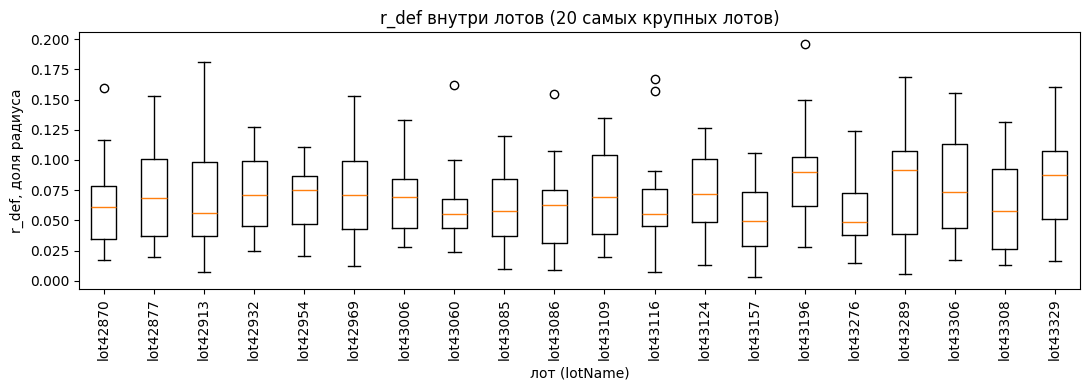

In [5]:
top = df["lotName"].value_counts().head(20).index
data = [df.loc[df["lotName"] == lot, "r_def"].dropna().values for lot in top]
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(data)
ax.set_xticks(range(1, len(top) + 1), top, rotation=90)
ax.set_xlabel("лот (lotName)")
ax.set_ylabel("r_def, доля радиуса")
ax.set_title("r_def внутри лотов (20 самых крупных лотов)")
plt.tight_layout()
plt.show()